# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

## Q-Learning for Room Navigation
### Reinforcement Learning

**Goal:** Train an agent to reach a destination room by moving through connected rooms.

1. Represent the rooms and doorways as states and actions.
2. Build the reward matrix and initialize the Q-table.
3. Use an epsilon-greedy strategy to select actions and update Q-values.
4. Train the agent and visualize how the Q-values change.
5. Follow the learned policy and compare its routes with the shortest possible routes.

* The agent receives a reward of 100 when it enters room 5.
* Each earlier move earns 0.
* With a discount factor between 0 and 1, reaching the goal sooner gives a higher discounted return.

## 1. Install the required libraries

Run this cell if NumPy, pandas, or Matplotlib is missing from your notebook environment. You can skip it if all three are already installed.

In [15]:
%pip -q install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries

* NumPy stores the reward and Q-values, pandas displays them as labeled tables, and Matplotlib plots the learning progress.
* The seed makes the training run reproducible when you run the notebook from top to bottom.

In [16]:
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display  # Renders rich objects (DataFrames, images, HTML) in Jupyter/IPython
seed = 42

## 3. Define the room environment

* Each room is a **state**.
* An **action** is the choice of a neighboring room to enter.
* For example, from room 2 the only move is to room 3.
* The room layout and graph below come from the supplied example.
* Room 5 is the **terminal state** in this notebook.
* The route ends as soon as the agent enters it.

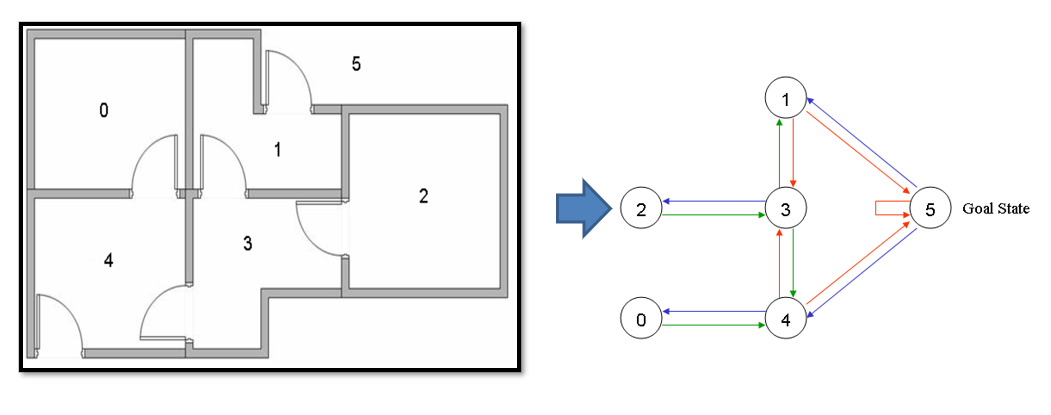

* The edge list describes the original graph.
* We keep the doors in that graph and give the terminal state an empty action list during training.

In [17]:
edges = [
    (0, 4), (4, 0),
    (1, 3), (3, 1),
    (1, 5), (5, 1),
    (2, 3), (3, 2),
    (3, 4), (4, 3),
    (4, 5), (5, 4),
    (5, 5),]

states = sorted({room for edge in edges for room in edge})
goal_state = 5

valid_actions = {state: [] for state in states}
for state, next_state in edges:
    if state != goal_state:
        valid_actions[state].append(next_state)

print("Number of rooms:", len(states))
print("Starting room for the example:", 2)
print("Goal room:", goal_state)
print("Available moves from each room:", valid_actions)

Number of rooms: 6
Starting room for the example: 2
Goal room: 5
Available moves from each room: {0: [4], 1: [3, 5], 2: [3], 3: [1, 2, 4], 4: [0, 3, 5], 5: []}


## 4. Build the reward matrix and initialize the Q-table

* Rows represent the current room. 
* Columns represent the room the agent chooses to enter.

- **Reward matrix** $R(s,a)$ gives the immediate reward for a move. 
    * Entering room 5 earns 100. 
    * Every other allowed move earns 0.
- **Q-table** $Q(s,a)$ estimates the discounted return from taking a move and then following the best available actions. 
    * Every allowed move starts at 0.
- A dash in either table marks a move that the agent cannot take. 
    * The row for room 5 is empty because reaching it ends the route.

In [18]:
n_states = len(states)
reward_matrix = np.full((n_states, n_states), np.nan)  # 2D state grid initialized with NaN placeholders
initial_q_table = np.full((n_states, n_states), np.nan)

for state, actions in valid_actions.items():
    for action in actions:
        reward_matrix[state, action] = 100.0 if action == goal_state else 0.0
        initial_q_table[state, action] = 0.0

state_index = pd.Index(states, name="Current room")
action_index = pd.Index(states, name="Next room")

print("Reward matrix")
display(pd.DataFrame(reward_matrix, index=state_index, columns=action_index).fillna("—"))

print("Initial Q-table")
display(pd.DataFrame(initial_q_table, index=state_index, columns=action_index).fillna("—"))

Reward matrix


Next room,0,1,2,3,4,5
Current room,,,,,,
0,—,—,—,—,0.0,—
1,—,—,—,0.0,—,100.0
2,—,—,—,0.0,—,—
3,—,0.0,0.0,—,0.0,—
4,0.0,—,—,0.0,—,100.0
5,—,—,—,—,—,—


Initial Q-table


Next room,0,1,2,3,4,5
Current room,,,,,,
0,—,—,—,—,0.0,—
1,—,—,—,0.0,—,0.0
2,—,—,—,0.0,—,—
3,—,0.0,0.0,—,0.0,—
4,0.0,—,—,0.0,—,0.0
5,—,—,—,—,—,—


## 5. Select an action and update its Q-value

**Epsilon-greedy action selection**

- With probability $\varepsilon$, **explore** by choosing a random allowed move.
- With probability $1-\varepsilon$, **exploit** by choosing the allowed move with the highest current Q-value. Break ties randomly during training.

**Q-learning update**

$$
Q(s,a) \leftarrow Q(s,a) + \alpha\left[\text{target} - Q(s,a)\right]
$$

For an ordinary move, the target is 

$$
r + \gamma \max_{a'} Q(s',a')
$$, 

- $r$: the immediate reward 
- $s'$: the next room
- $\alpha$: the **learning rate** and controls how far the estimate moves toward the target.
- $\gamma$: the **discount factor** and controls how much future rewards count.

For example, on the first update for $4 \rightarrow 5$, a learning rate of 0.1 moves the Q-value from 0 to 10 because the target is 100.

In [19]:
def choose_action(state, q_table, epsilon, rng):
    actions = np.array(valid_actions[state])

    # Explore by sampling from the allowed moves.
    if rng.random() < epsilon:
        return int(rng.choice(actions))

    # Exploit the largest Q-value, breaking ties randomly.
    action_values = q_table[state, actions]
    best_actions = actions[action_values == action_values.max()]
    return int(rng.choice(best_actions))


def update_q_value(q_table, state, action, learning_rate, discount_factor):
    target = reward_matrix[state, action]

    # Here the chosen action also identifies the next room.
    if action != goal_state:
        next_actions = valid_actions[action]
        target += discount_factor * q_table[action, next_actions].max()

    q_table[state, action] += learning_rate * (target - q_table[state, action])

## 6. Train the agent and inspect the learned Q-table

* Each training update samples a nonterminal room, chooses one move, and updates the corresponding Q-value. 
* This follows the one-step sampling loop in the supplied code. 
* The settings below use 500 updates, a learning rate of 0.1, and a discount factor of 0.8. 
* During training, the agent explores with probability 0.8.

We record three Q-values along one possible route so we can see how information about the goal spreads to earlier rooms.

In [20]:
learning_rate = 0.1
discount_factor = 0.8
epsilon = 0.8
n_updates = 500

rng = np.random.default_rng(seed)
q_table = initial_q_table.copy()
training_states = [state for state in states if state != goal_state]

tracked_moves = [(4, 5), (3, 4), (2, 3)]
q_history = {move: [q_table[move]] for move in tracked_moves}

for _ in range(n_updates):
    state = int(rng.choice(training_states))
    action = choose_action(state, q_table, epsilon, rng)
    update_q_value(q_table, state, action, learning_rate, discount_factor)

    for move in tracked_moves:
        q_history[move].append(q_table[move])

print("Training updates:", n_updates)
print("Learned Q-table")
display(pd.DataFrame(q_table, index=state_index, columns=action_index).round(2).fillna("—"))

Training updates: 500
Learned Q-table


Next room,0,1,2,3,4,5
Current room,,,,,,
0,—,—,—,—,79.36,—
1,—,—,—,53.7,—,99.8
2,—,—,—,59.41,—,—
3,—,76.28,37.73,—,68.15,—
4,45.36,—,—,51.51,—,99.58
5,—,—,—,—,—,—


## 7. Visualize how the Q-values change

* The move from room 4 to room 5 earns the goal reward directly.
* The earlier moves gain value as the agent learns the value of the rooms they lead to.
* For the route 2 -> 3 -> 4 -> 5, the optimal Q-values for these moves are $100\gamma^2$, $100\gamma$, and $100$, respectively. 
* Compare these targets with the estimates after 500 updates.

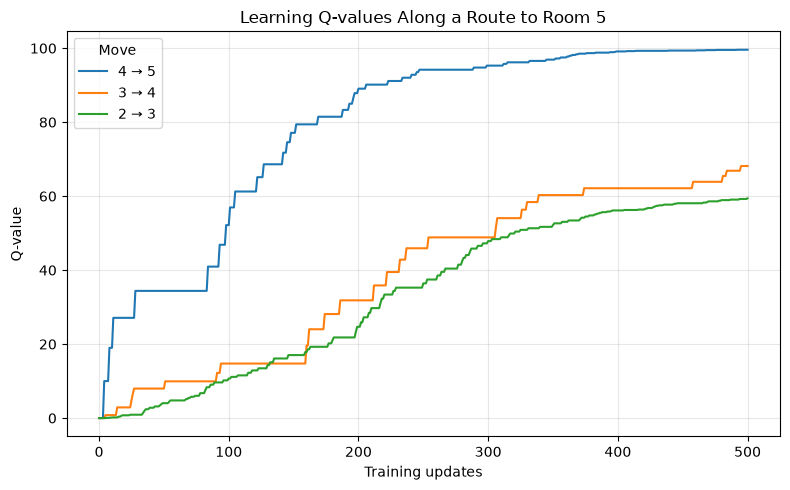

In [21]:
plt.figure(figsize=(8, 5))

for (state, action), values in q_history.items():
    plt.plot(values, label=f"{state} → {action}")

plt.xlabel("Training updates")
plt.ylabel("Q-value")
plt.title("Learning Q-values Along a Route to Room 5")
plt.legend(title="Move")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Follow the learned policy

* At evaluation time, choose the best allowed move at each room. 
* If values tie exactly, choose the lowest-numbered destination for reproducibility. 
* Stop at room 5 or report a cycle if the policy revisits a room. 
* A cycle can occur when the agent has had too few training updates.

* Starting from room 2, both 2 -> 3 -> 1 -> 5 and 2 -> 3 -> 4 -> 5 are shortest routes. 
* The learned policy can pick either one.

In [23]:
def greedy_path(start_state, q_table):
    path = [start_state]

    while path[-1] != goal_state:
        state = path[-1]
        actions = sorted(valid_actions[state])
        best_action_index = np.argmax(q_table[state, actions])
        next_state = actions[best_action_index]

        if next_state in path:
            return path + [next_state], False

        path.append(next_state)

    return path, True


start_state = 2
path, reached_goal = greedy_path(start_state, q_table)

print("Learned route:", " -> ".join(map(str, path)))
print("Goal reached:", reached_goal)
if reached_goal:
    print("Number of moves:", len(path) - 1)
else:
    print("The policy revisited a room before reaching the goal.")

Learned route: 2 -> 3 -> 1 -> 5
Goal reached: True
Number of moves: 3
